# 04 · Frente de onda y límite de difracción

Extra 5. El trazado de rayos dice dónde cruza cada rayo; la óptica ondulatoria dice si eso importa. Si todos los rayos llegaran a la imagen con el mismo **camino óptico** (principio de Fermat), las ondas llegarían en fase y la imagen de un punto sería el patrón de difracción de la apertura (disco de Airy). La diferencia de camino de cada rayo es el **error del frente de onda** $W$; con él se decide si la lente está limitada por la difracción o por la aberración.

**Supuestos.** Las longitudes del proyecto se leen como milímetros y la luz es verde, $\lambda = 550$ nm. Objeto en el eje, en $y = -30$ (el del ejemplo resuelto). Difracción escalar y pupila circular iluminada de forma uniforme, con el diafragma en la cara $g$. La pupila completa llega hasta $h = 3.92$ mm, la misma del notebook 02.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from lentes import focal_efectiva, lente_biconvexa
from lentes.aberraciones import y_paraxial
from lentes.difraccion import (LAMBDA_VERDE, MARECHAL, apertura_cruce, apertura_limite, apertura_numerica,
                               conica_optima, haz, mejor_foco_onda, psf, radio_airy, radio_rms_geometrico,
                               strehl, strehl_marechal)
from lentes.estilo import RAMPA_AZUL, TINTA_2, aplicar_estilo
from lentes.seidel import k_que_anula, suma_seidel

aplicar_estilo()
lam, y_obj = LAMBDA_VERDE, -30.0


def con_conica(k):
    """La lente de trabajo con la misma constante cónica k en las dos caras."""
    return lente_biconvexa(10, 10, 2.0, 1.5, k, k)


H_MAX = 0.9 * min(con_conica(-1.0).semiapertura, con_conica(0.0).semiapertura)
k_cero = k_que_anula(con_conica(0.0), y_obj)
k_opt, _ = conica_optima(con_conica, y_obj, H_MAX, cerca_de=k_cero)
lentes = {"esfera": con_conica(0.0), "parábola": con_conica(-1.0),
          "cónica k0": con_conica(k_cero), "cónica óptima": con_conica(k_opt)}
haces = {nombre: haz(lente, y_obj) for nombre, lente in lentes.items()}
print(f"Pupila completa: h = {H_MAX:.2f} mm")
print(f"Cónica que anula el tercer orden: k0 = {k_cero:.4f}")
print(f"Cónica de menor W_rms con la pupila completa: k = {k_opt:.4f} (sección 5)")

Pupila completa: h = 3.92 mm
Cónica que anula el tercer orden: k0 = -2.3294
Cónica de menor W_rms con la pupila completa: k = -2.3454 (sección 5)


## 1. Camino óptico y error del frente de onda

Para cada rayo se suma $n \cdot \ell$ a lo largo de su recorrido: aire hasta la cara $g$, vidrio hasta la cara $f$ y aire hasta una **esfera de referencia** centrada en el punto imagen que pasa por el vértice de salida. Si la lente fuera perfecta, esa esfera sería un frente de onda y todos los caminos serían iguales. Con la convención de los libros,

$$W(h) = \mathrm{OPL}(\text{rayo axial}) - \mathrm{OPL}(\text{rayo que entra a la altura } h).$$

En tercer orden la teoría de Seidel predice $W = \tfrac{S_I}{8}\,h^4$ con la referencia en la imagen paraxial. Es un tercer cálculo de la misma aberración: el primero fue dónde cruzan los rayos (notebook 02) y el segundo la suma de Seidel. El camino óptico usa los mismos rayos trazados que el primero, pero mide otra cosa (fases en lugar de cruces); la suma de Seidel no usa el trazado.

In [2]:
for nombre in ("esfera", "parábola"):
    lente, hz = lentes[nombre], haces[nombre]
    hs = np.linspace(0.02, 0.3, 15)
    W = hz.frente_de_onda(hs, y_paraxial(lente, y_obj))
    c4 = np.linalg.lstsq(np.vstack([hs**2, hs**4, hs**6, hs**8]).T, W, rcond=None)[0][1]
    print(f"{nombre:9s}  W040 por Fermat = {c4:.6e} mm   S_I/8 de Seidel = {suma_seidel(lente, y_obj) / 8:.6e} mm"
          f"   cociente = {c4 / (suma_seidel(lente, y_obj) / 8):.7f}")

esfera     W040 por Fermat = 2.794958e-04 mm   S_I/8 de Seidel = 2.794956e-04 mm   cociente = 1.0000005
parábola   W040 por Fermat = 1.595098e-04 mm   S_I/8 de Seidel = 1.595097e-04 mm   cociente = 1.0000008


## 2. El mejor foco para las ondas está a mitad de camino

Moverse a lo largo del eje agrega un término de desenfoque $W_{020}\rho^2$. Con $W = W_{040}\rho^4 + W_{020}\rho^2$, el menor $W_\text{rms}$ se logra con $W_{020} = -W_{040}$: a **mitad de camino** entre el foco paraxial y el marginal, y ese RMS es **la cuarta parte** del que hay en el foco paraxial ($\sqrt{1/180}$ frente a $\sqrt{4/45}$). El notebook 02 mostró que la mancha geométrica más chica está a 2/3 y el círculo de mínima confusión a 3/4: el "mejor foco" depende de qué se quiera medir.

In [3]:
hz = haces["parábola"]
for h_max in (0.3, 2.0):
    f = mejor_foco_onda(hz, h_max)
    print(f"h_max = {h_max}:  mejor foco en la fracción {f.fraccion(f.y_ref):.4f} del camino paraxial → marginal; "
          f"W_rms = {f.rms / lam:.4f} λ (en el foco paraxial: {f.rms_paraxial / lam:.4f} λ, cociente {f.rms / f.rms_paraxial:.4f})")

h_max = 0.3:  mejor foco en la fracción 0.4999 del camino paraxial → marginal; W_rms = 0.0002 λ (en el foco paraxial: 0.0007 λ, cociente 0.2501)
h_max = 2.0:  mejor foco en la fracción 0.4957 del camino paraxial → marginal; W_rms = 0.3520 λ (en el foco paraxial: 1.3710 λ, cociente 0.2568)


## 3. ¿Hasta qué apertura manda la difracción?

**Criterio de Maréchal:** una lente está limitada por la difracción si $W_\text{rms} \le \lambda/14$, lo que equivale a un **Strehl** (pico de la imagen de un punto dividido por el de una lente perfecta) de 0.8. El Strehl exacto se calcula con la integral de difracción de la pupila circular,

$$S = \left|\int_0^1 2\rho\, e^{\,i\,2\pi W(\rho)/\lambda}\, d\rho\right|^2,$$

y la aproximación de Maréchal es $S \approx e^{-(2\pi W_\text{rms}/\lambda)^2}$.

La otra forma de verlo: la mancha geométrica crece como $h^3$ y el disco de Airy, $0.61\,\lambda/\mathrm{NA}'$, se achica como $1/h$. Donde se cruzan cambia quién manda.

En la tabla, $h^*$ es el mayor radio de apertura que cumple Maréchal y $D^* = 2h^*$. Se dan dos números f: el **de trabajo**, $N_w = 1/(2\,\mathrm{NA}')$, con la apertura numérica del rayo marginal que sale hacia la imagen (objeto en $y = -30$), y el **nominal** $f/D^*$, con la focal efectiva $f = 10.345$. El Strehl de las últimas columnas se calcula en el plano de menor $W_\text{rms}$; con mucha aberración ese plano no es el de pico más alto.

In [4]:
f_ef = focal_efectiva(lentes["esfera"])
print(f"{'lente':14s} {'h* (mm)':>8s} {'D* (mm)':>8s} {'N_w':>5s} {'f/D*':>5s} {'Airy (μm)':>10s} {'cruce (mm)':>11s}"
      f" {'W_rms h=' + format(H_MAX, '.2f') + ' (λ)':>17s} {'Strehl':>7s}")
for nombre, hz in haces.items():
    h_lim = apertura_limite(hz)
    try:
        cruce = f"{apertura_cruce(hz):11.2f}"
    except ValueError:  # la mancha geométrica nunca alcanza al disco de Airy
        cruce = f"{'no se cruzan':>11s}"
    na = apertura_numerica(hz, h_lim)
    fH = mejor_foco_onda(hz, H_MAX)
    toda = " (cumple hasta el tope del cálculo, el 95 % del borde)" if h_lim == hz.h_tope else ""
    print(f"{nombre:14s} {h_lim:8.2f} {2 * h_lim:8.2f} {1 / (2 * na):5.2f} {f_ef / (2 * h_lim):5.2f}"
          f" {radio_airy(hz, h_lim) * 1e3:10.2f} {cruce} {fH.rms / lam:17.3f} {strehl(hz, H_MAX, fH.y_ref):7.3f}{toda}")

lente           h* (mm)  D* (mm)   N_w  f/D*  Airy (μm)  cruce (mm)  W_rms h=3.92 (λ)  Strehl
esfera             1.17     2.34  6.52  4.43       4.38        1.15            10.423   0.004
parábola           1.35     2.69  5.70  3.84       3.83        1.33             5.437   0.007
cónica k0          4.09     8.19  2.02  1.26       1.35        3.92             0.057   0.877
cónica óptima      4.39     8.78  1.90  1.18       1.28 no se cruzan             0.007   0.998 (cumple hasta el tope del cálculo, el 95 % del borde)


In [5]:
for nombre in ("esfera", "parábola"):
    hz = haces[nombre]
    geo, airy = radio_rms_geometrico(hz, H_MAX), radio_airy(hz, H_MAX)
    print(f"{nombre}, pupila completa: mancha geométrica RMS {geo * 1e3:.0f} μm, disco de Airy {airy * 1e3:.2f} μm"
          f" ({geo / airy:.0f} veces)")
hz = haces["parábola"]
for h_max in (0.8, 1.0, 1.2, apertura_limite(hz)):
    f = mejor_foco_onda(hz, h_max)
    print(f"h_max = {h_max:.3f}:  Strehl exacto = {strehl(hz, h_max, f.y_ref):.4f}   Maréchal = {strehl_marechal(f.rms / lam):.4f}")

esfera, pupila completa: mancha geométrica RMS 214 μm, disco de Airy 1.05 μm (203 veces)
parábola, pupila completa: mancha geométrica RMS 113 μm, disco de Airy 1.21 μm (94 veces)


h_max = 0.800:  Strehl exacto = 0.9969   Maréchal = 0.9969
h_max = 1.000:  Strehl exacto = 0.9815   Maréchal = 0.9816
h_max = 1.200:  Strehl exacto = 0.9224   Maréchal = 0.9228
h_max = 1.346:  Strehl exacto = 0.8152   Maréchal = 0.8176


## 4. La imagen de un punto

La intensidad a la distancia $r$ del eje, en el mejor foco, es la integral de difracción de la pupila con la fase $2\pi W/\lambda$ (cada anillo de rayos aporta con $J_0(k\,r\,\sin\theta)$). Se normaliza al pico de una lente perfecta de la misma apertura, así que en $r = 0$ vale el Strehl. Con poca apertura se ve el patrón de Airy; con mucha, la aberración se come el pico y reparte la luz en anillos.

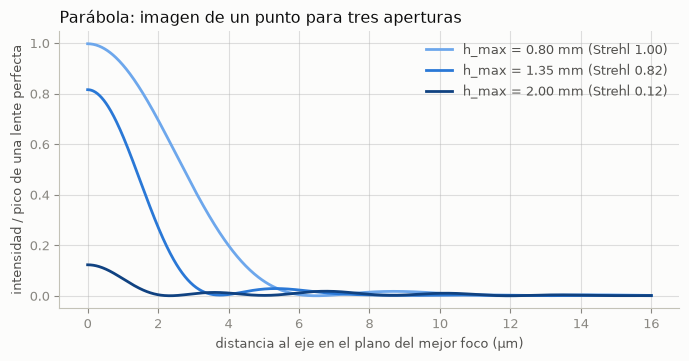

In [6]:
r = np.linspace(0, 16, 800)  # μm
fig, ax = plt.subplots(figsize=(8, 3.6))
for h_max, color in ((0.8, RAMPA_AZUL[1]), (apertura_limite(hz), RAMPA_AZUL[4]), (2.0, RAMPA_AZUL[8])):  # más oscuro = más apertura
    f = mejor_foco_onda(hz, h_max)
    ax.plot(r, psf(hz, h_max, f.y_ref, r * 1e-3), color=color, lw=2,
            label=f"h_max = {h_max:.2f} mm (Strehl {strehl(hz, h_max, f.y_ref):.2f})")
ax.set_xlabel("distancia al eje en el plano del mejor foco (μm)")
ax.set_ylabel("intensidad / pico de una lente perfecta")
ax.set_title("Parábola: imagen de un punto para tres aperturas", loc="left")
ax.legend(frameon=False, labelcolor=TINTA_2)
ax.grid(True, alpha=0.4)
plt.show()

## 5. La mejor cónica y su tolerancia

$k_0$ anula el término $\rho^4$ del frente de onda, pero con la pupila completa quedan los de orden superior ($\rho^6$, $\rho^8$...). Rinde más dejar un poco de tercer orden de signo contrario que los compense: la cónica de menor $W_\text{rms}$ es algo más negativa que $k_0$. Con ella la aberración cambia de signo entre el centro y el borde (aberración **zonal**) y el mejor foco queda fuera del tramo entre el foco paraxial y el del borde.

La **tolerancia de fabricación** sale del mismo criterio: el rango de $k$ con el que toda la pupila sigue limitada por la difracción. Un error en $k$ cambia sobre todo el tercer orden, que crece como $h^4$.

In [7]:
def w_rms(k):
    return mejor_foco_onda(haz(con_conica(k), y_obj, h_tope=H_MAX), H_MAX)


f_cero, f_opt = w_rms(k_cero), w_rms(k_opt)
print(f"k0 = {k_cero:.4f}: W_rms = {f_cero.rms / lam:.4f} λ")
print(f"k  = {k_opt:.4f}: W_rms = {f_opt.rms / lam:.4f} λ ({f_cero.rms / f_opt.rms:.1f} veces menos)")
print(f"   con la óptima el mejor foco está en y = {f_opt.y_ref:.4f}, fuera del tramo entre el foco paraxial"
      f" ({f_opt.y_paraxial:.4f}) y el del borde ({f_opt.y_marginal:.4f})")

k_bajo = brentq(lambda k: w_rms(k).rms / lam - MARECHAL, k_opt - 0.1, k_opt, xtol=1e-7)
k_alto = brentq(lambda k: w_rms(k).rms / lam - MARECHAL, k_opt, k_opt + 0.1, xtol=1e-7)
print(f"\nToda la pupila limitada por difracción con {k_bajo:.3f} <= k <= {k_alto:.3f}:"
      f" ±{50 * (k_alto - k_bajo) / abs(k_opt):.2f} % alrededor de la óptima")
for factor, texto in ((1.01, "1 % más negativo"), (0.99, "1 % menos negativo")):
    print(f"k0 {texto} (k = {factor * k_cero:.4f}): W_rms = {w_rms(factor * k_cero).rms / lam:.3f} λ")

k0 = -2.3294: W_rms = 0.0574 λ
k  = -2.3454: W_rms = 0.0073 λ (7.8 veces menos)
   con la óptima el mejor foco está en y = 16.1921, fuera del tramo entre el foco paraxial (16.1872) y el del borde (16.1881)



Toda la pupila limitada por difracción con -2.365 <= k <= -2.325: ±0.85 % alrededor de la óptima


k0 1 % más negativo (k = -2.3527): W_rms = 0.027 λ


k0 1 % menos negativo (k = -2.3061): W_rms = 0.140 λ


## Qué muestra

- El camino óptico (Fermat), la suma de Seidel y el cruce de los rayos dan la misma aberración de tercer orden. Son tres cálculos distintos; Seidel es el único que no usa el trazado (`tests/test_difraccion.py`).
- Con la pupila completa ($h = 3.92$ mm), la parábola tiene un error de frente de onda de unas 5 longitudes de onda y la esfera de 10: la imagen la limita la aberración, no la difracción.
- Cerrando la apertura a unos 2.3 mm de diámetro (esfera) o 2.7 mm (parábola) la lente pasa a estar limitada por la difracción. Los dos criterios (Maréchal y mancha = Airy) dan casi la misma apertura.
- La cónica que anula el tercer orden queda limitada por difracción hasta 8.2 mm de diámetro: unas 12 veces más luz que la esfera y un disco de Airy unas 3 veces menor. La cónica óptima lo logra hasta el 95 % del borde, donde termina el cálculo. Por eso las cámaras de los celulares y los telescopios usan superficies asféricas.
- Para que toda la pupila siga limitada por difracción, $k$ tiene que estar a menos de 0.85 % de la óptima: un error como el del espejo del telescopio Hubble (1.2 %) ya la sacaría de ese límite.
- Une el trazado de rayos con la difracción del curso: el disco de Airy es la versión circular del patrón de una rendija.

Límites: difracción escalar, luz de un solo color y pupila uniforme; el resultado depende de leer las longitudes como milímetros (una lente 10 veces más grande tendría 10 veces más aberración medida en longitudes de onda).